In [2]:
#!pip install requests beautifulsoup4 plotly

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Used in the advanced topic (web scraping and interactive maps)
import os
import time
import requests
import bs4
from bs4 import BeautifulSoup
import plotly
import plotly.express as px

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
# Versions of the packages used
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('matplotlib:', plt.matplotlib.__version__)
print('seaborn:', sns.__version__)
print('requests:', requests.__version__)
print('beautifulsoup4:', bs4.__version__)
print('plotly:', plotly.__version__)

pandas: 3.0.5
numpy: 2.5.2
matplotlib: 3.11.2
seaborn: 0.13.2
requests: 2.34.2
beautifulsoup4: 4.15.0
plotly: 6.0.0


In [4]:
sns.set_style('whitegrid')
sns.set_palette('Set2')

## 1. Data loading

In [5]:
# Import dataset
df = pd.read_csv('artist_streams.csv',sep=',',parse_dates=['Update Date'])
df

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01,2026.0
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01,2026.0
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01,2026.0
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01,2026.0
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01,2026.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
506,496,The Marías,NaN,United States,English,Pop,Group,2017.0,7029.1,5774.4,1261.4,5705.9,1323.2,2026-07-01,2026.0
507,497,Limp Bizkit,Male,United States,English,Nu Metal,Group,1997.0,7018.9,7018.4,5.4,6806.0,212.9,2026-07-01,2026.0
508,498,Korn,Male,United States,English,Metal,Group,1994.0,6976.4,4188.4,2798.5,6414.9,561.5,2026-07-01,2026.0
509,499,Omar Courtz,Male,United States,Spanish,Reggaeton,Solo,2017.0,6972.0,6956.0,20.3,1876.2,5095.8,2026-07-01,2026.0


In [6]:
df.sample(5)

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
32,32,21 Savage,Male,United Kingdom,English,Hip-Hop,Solo,2014.0,39024.3,15878.0,23155.6,7883.1,31141.2,2026-07-01,2026.0
244,240,Frank Sinatra,Male,United States,English,Pop,Solo,1939.0,12421.7,11999.7,421.9,9162.6,3259.1,2026-07-01,2026.0
333,324,Nickelback,Male,Canada,English,Rock,Group,1996.0,9933.4,9932.9,6.1,9864.7,68.7,2026-07-01,2026.0
173,171,Bob Marley & The Wailers,Male,Jamaica,English,Reggae,Group,1962.0,14992.7,14837.1,161.6,13836.0,1156.7,2026-07-01,2026.0
172,170,Justin Quiles,Male,United States,Spanish,Reggaeton,Solo,2010.0,15041.1,4978.9,10062.1,2069.9,12971.2,2026-07-01,2026.0


In [7]:
print('Initial Dimensions:', df.shape)

Initial Dimensions: (511, 15)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 511 entries, 0 to 510
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Artist ID              511 non-null    int64         
 1   Artist Name            510 non-null    str           
 2   Sex                    486 non-null    str           
 3   Country of Origin      510 non-null    str           
 4   Primary Language       510 non-null    str           
 5   Primary Genre          510 non-null    str           
 6   Artist Type            510 non-null    str           
 7   Debut Year             510 non-null    float64       
 8   Total Streams          505 non-null    float64       
 9   Lead Streams           504 non-null    float64       
 10  Feature Streams        499 non-null    float64       
 11  Solo Streams           506 non-null    float64       
 12  Collaborative Streams  509 non-null    float64       
 13  Update Date     

In [9]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Artist ID,511.0,249.956947,0.0,126.5,251.0,373.5,500.0,144.020444
Debut Year,510.0,2005.201961,1939.0,2001.0,2009.0,2014.0,2023.0,13.359191
Total Streams,505.0,16792.430891,6972.0,8809.4,11966.9,17738.8,137492.1,14771.249974
Lead Streams,504.0,12167.685516,0.0,6489.75,8756.7,13456.9,126177.3,11833.059565
Feature Streams,499.0,4675.36493,0.0,702.8,2993.2,6096.5,43710.5,5954.390999
Solo Streams,506.0,8348.897628,0.0,2505.925,6472.95,10127.05,113421.5,9600.760173
Collaborative Streams,509.0,8434.201768,0.0,1996.6,6578.1,10929.4,84168.2,9551.041044
Update Date,510,2026-06-23 20:14:07.058823,2025-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,2026-07-01 00:00:00,NaN
Year,510.0,2026.0,2026.0,2026.0,2026.0,2026.0,2026.0,0.0


First observations:
- There are 511 rows, but the `Artist ID` only goes from 0 to 500, so some rows must be repeated.
- Almost all columns have missing values.
- `Debut Year` and `Year` are floats and `Update Date` is text, so the types need to be fixed.
- The stream columns (in millions) have a mean much higher than the median, so a few artists have a lot more streams than the others.

## 2. Data Wrangling and Analysis

### Q1 – Duplicates, missing values and other data quality issues

#### Duplicates

In [10]:
# Number of duplicated rows
df.duplicated().sum()

np.int64(10)

In [11]:
# See the duplicated rows
df[df.duplicated(keep=False)]

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
45,45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01,2026.0
46,45,Linkin Park,NaN,United States,English,Rock,Group,2000.0,33224.7,31426.6,1798.1,30151.2,3073.5,2026-07-01,2026.0
141,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01,2026.0
142,140,Fleetwood Mac,NaN,United Kingdom,English,Rock,Group,1967.0,16577.5,16577.5,NaN,16567.4,10.1,2026-07-01,2026.0
220,218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01,2026.0
221,218,John Mayer,Male,United States,English,Pop,Solo,1999.0,13208.3,12134.4,1076.8,11821.4,1386.9,2026-07-01,2026.0
224,221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01,2026.0
225,221,System Of A Down,Male,United States,English,Metal,Group,1998.0,13009.4,13017.1,0.0,12963.5,45.9,2026-07-01,2026.0
267,263,Zedd,Male,Russia,English,EDM,Solo,2010.0,11481.4,11486.5,0.0,235.7,11245.7,2026-07-01,2026.0
268,263,Zedd,Male,Russia,English,EDM,Solo,2010.0,11481.4,11486.5,0.0,235.7,11245.7,2026-07-01,2026.0


There are 10 rows that are exact copies of other rows (same ID and same values in every column). If we kept them, these artists would be counted twice, so we remove them.

In [12]:
df = df.drop_duplicates()

# Check that each ID and each name now appears only once
print(df['Artist ID'].duplicated().sum())
print(df['Artist Name'].duplicated().sum())

0
0


#### Missing values

In [13]:
df.isna().sum()

Artist ID                 0
Artist Name               1
Sex                      23
Country of Origin         1
Primary Language          1
Primary Genre             1
Artist Type               1
Debut Year                1
Total Streams             6
Lead Streams              7
Feature Streams          10
Solo Streams              5
Collaborative Streams     2
Update Date               1
Year                      1
dtype: int64

In [14]:
# The row with the missing Artist Name
df[df['Artist Name'].isna()]

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
510,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN


This row only has an ID and no other information, so we drop it.

In [15]:
df = df.drop(index=510)
df.isna().sum()

Artist ID                 0
Artist Name               0
Sex                      22
Country of Origin         0
Primary Language          0
Primary Genre             0
Artist Type               0
Debut Year                0
Total Streams             5
Lead Streams              6
Feature Streams           9
Solo Streams              4
Collaborative Streams     1
Update Date               0
Year                      0
dtype: int64

**Missing stream values**
- Total Streams = Solo Streams + Collaborative Streams
- Total Streams = Lead Streams + Feature Streams


In [16]:
diff_solo = df['Total Streams'] - (df['Solo Streams'] + df['Collaborative Streams'])
diff_lead = df['Total Streams'] - (df['Lead Streams'] + df['Feature Streams'])

print('Total - (Solo + Collaborative):')
print(diff_solo.describe().round(2))
print('\nTotal - (Lead + Feature):')
print(diff_lead.describe().round(2))

Total - (Solo + Collaborative):
count    490.0
mean      -0.0
std        0.0
min       -0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
dtype: float64

Total - (Lead + Feature):
count    480.00
mean      -5.37
std        9.37
min      -39.20
25%       -9.15
50%       -5.00
75%       -1.27
max       89.20
dtype: float64


- Solo + Collaborative is always exactly equal to Total.
- Lead + Feature is almost equal to Total (the difference is at most around 90 million, which is less than 1% of the streams of the artist).

Instead of dropping the rows or filling them with the mean, we can use these formulas to calculate the missing values from the other columns of the same row. First we check that no row has more than one missing stream value.

In [17]:
df[['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']].isna().sum(axis=1).value_counts()
# 475 artistas nao tÊm nenum valor nulo em nenhuma das 5 colunas
# 25 artistas têm 1 valor nulo em uma das 5 colunas

0    475
1     25
Name: count, dtype: int64

In [18]:
# Rows with a missing stream value (to check them after filling)
missing_rows = df[df[['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']].isna().sum(axis=1) > 0].index
missing_rows

Index([ 16,  47,  57, 107, 124, 131, 141, 169, 178, 185, 214, 227, 277, 293,
       297, 335, 343, 359, 377, 393, 395, 430, 482, 485, 494],
      dtype='int64')

In [19]:
df['Total Streams'] = df['Total Streams'].fillna(df['Solo Streams'] + df['Collaborative Streams'])
df['Solo Streams'] = df['Solo Streams'].fillna(df['Total Streams'] - df['Collaborative Streams'])
df['Collaborative Streams'] = df['Collaborative Streams'].fillna(df['Total Streams'] - df['Solo Streams'])
df['Lead Streams'] = df['Lead Streams'].fillna(df['Total Streams'] - df['Feature Streams'])
df['Feature Streams'] = df['Feature Streams'].fillna(df['Total Streams'] - df['Lead Streams'])

df.loc[missing_rows, ['Artist Name','Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
16,Future,53951.5,27879.0,26072.5,12647.5,41304.0
47,Peso Pluma,33179.8,18699.1,14501.2,3938.3,29241.5
57,Harry Styles,29449.0,29462.8,-13.8,29449.0,0.0
107,Kygo,19707.8,17824.5,1883.3,250.7,19457.1
124,Sean Paul,18203.3,9663.9,8539.4,4460.6,13742.7
131,Bebe Rexha,17440.2,5928.1,11512.1,2784.0,14656.2
141,Fleetwood Mac,16577.5,16577.5,0.0,16567.4,10.1
169,A.R. Rahman,15240.4,10857.5,4397.5,594.9,14645.5
178,ROSALÍA,14558.4,10084.0,4474.4,5316.8,9241.6
185,Panic! At The Disco,14402.3,4417.2,9985.1,13038.0,1364.3


**Missing `Sex`.**

In [20]:
df[df['Sex'].isna()]['Artist Type'].value_counts()

Artist Type
Group    22
Name: count, dtype: int64

In [21]:
df[df['Sex'].isna()]['Artist Name'].values

<ArrowStringArray>
[               'Maroon 5',             'Linkin Park',
           'One Direction',                  'Disney',
   'Red Hot Chili Peppers',             'OneRepublic',
           'Fleetwood Mac',         'Black Eyed Peas',
    'Cigarettes After Sex',             'Major Lazer',
                    'ABBA',                'Paramore',
            'Clean Bandit',       'League of Legends',
                    'Maná',                'Måneskin',
               'SEVENTEEN',         'Backstreet Boys',
               'Aerosmith',      'Los Ángeles Azules',
 'Macklemore & Ryan Lewis',              'The Marías']
Length: 22, dtype: str

All 22 missing values are groups. Some of these groups have men and women (ABBA, Fleetwood Mac, Black Eyed Peas, Paramore) and some are not people at all (Disney, League of Legends). Filling them with "Male" (the most common value) would be wrong, so we create a new category `Mixed/Unknown`.

In [22]:
df['Sex'] = df['Sex'].fillna('Mixed/Unknown')
df['Sex'].value_counts()

Sex
Male             390
Female            88
Mixed/Unknown     22
Name: count, dtype: int64

#### Data types

In [23]:
df['Debut Year'] = df['Debut Year'].astype(int) # Debut year estava como float
df['Year'] = df['Year'].astype(int)  # Year estava como float
df.dtypes

Artist ID                         int64
Artist Name                         str
Sex                                 str
Country of Origin                   str
Primary Language                    str
Primary Genre                       str
Artist Type                         str
Debut Year                        int64
Total Streams                   float64
Lead Streams                    float64
Feature Streams                 float64
Solo Streams                    float64
Collaborative Streams           float64
Update Date              datetime64[us]
Year                              int64
dtype: object

#### Other data quality issues
We look at the unique values of the text columns to find errors.

In [24]:
print(df['Primary Genre'].unique())

<ArrowStringArray>
[         'Hip-Hop',              'Pop',        'Reggaeton',
              'R&B',            'K-Pop',             'Rock',
      'Alternative',              'EDM',            'Filmi',
            'Latin', 'Regional Mexican',          'Country',
      'Spoken Word',       'Soundtrack',          'Bachata',
        'Sertanjeo',           'Reggae',             'Folk',
            'Metal',        'Afrobeats',             'Soul',
 'Children's Music',         'Nu Metal']
Length: 23, dtype: str


In [25]:
print(df['Country of Origin'].unique())

<ArrowStringArray>
[             'Canada',       'United States',      'United Kingdom',
            'Barbados',            'Colombia',         'South Korea',
 'Trinidad and Tobago',              'France',               'India',
            'Scotland',              'Mexico',           'Australia',
             'Germany',                'Cuba',              'Sweden',
              'Norway',              'Panama',              'Brazil',
         'Netherlands',             'Jamaica',             'Senegal',
             'Ireland',           'Argentina',               'Spain',
               'Japan',         'New Zealand',             'Morocco',
               'Chile',              'Russia',             'Nigeria',
        'South Africa',           'Venezuela',               'Italy',
  'Dominican Republic',             'Belgium',            'DR Congo',
               'Nepal',            'Pakistan',           'Guatemala',
             'Austria',         'Philippines',             'Denmark',
 

In [26]:
print(df['Primary Language'].unique())

<ArrowStringArray>
[   'English',    'Spanish',     'Korean',      'Hindi',     'German',
 'Portuguese',      'Tamil',     'French',    'Italian',       'Urdu',
    'Punjabi']
Length: 11, dtype: str


In [27]:
print(df['Artist Type'].unique())

<ArrowStringArray>
['Solo', 'Group']
Length: 2, dtype: str


Problems found:
- `Sertanjeo` is a spelling mistake. The genre is **Sertanejo**.
- `Scotland` appears as a country (Calvin Harris, Lewis Capaldi), but all other British artists are `United Kingdom`. We use `United Kingdom` so the UK isn't split in two.
- `Nu Metal` has only 1 artist and is a sub-genre of Metal, so we join it with `Metal`.

In [28]:
df['Primary Genre'] = df['Primary Genre'].replace({'Sertanjeo': 'Sertanejo', 'Nu Metal': 'Metal'})
df['Country of Origin'] = df['Country of Origin'].replace({'Scotland': 'United Kingdom'})

**Negative values and parts bigger than the total.**

In [29]:
print('Negative values:', (df[['Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']] < 0).sum().sum())

Negative values: 2


In [30]:
print('Lead Streams bigger than Total Streams:', (df['Lead Streams'] > df['Total Streams']).sum())

Lead Streams bigger than Total Streams: 38


In [31]:
df[df['Lead Streams'] > df['Total Streams']][['Artist Name', 'Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
57,Harry Styles,29449.0,29462.8,-13.8,29449.0,0.0
60,One Direction,28889.5,28898.2,0.0,28801.9,87.6
63,Adele,28690.5,28699.5,0.0,28537.7,152.8
67,Arctic Monkeys,28155.4,28166.2,0.0,28130.4,25.0
73,The Beatles,26130.5,26138.7,2.2,26123.0,7.5
92,Red Hot Chili Peppers,21873.8,21884.2,0.0,21872.4,1.4
136,AC/DC,17010.5,17018.0,0.0,17010.5,0.0
145,Radiohead,16454.9,16461.5,3.0,16382.5,72.4
149,Nirvana,16228.7,16236.0,0.0,16228.7,0.0
194,Lewis Capaldi,14087.8,14091.2,0.0,13608.5,479.3


In [32]:
print('Feature Streams bigger than Total Streams:', (df['Feature Streams'] > df['Total Streams']).sum())

Feature Streams bigger than Total Streams: 1


In [33]:
df[df['Feature Streams'] > df['Total Streams']][['Artist Name','Total Streams', 'Lead Streams', 'Feature Streams', 'Solo Streams', 'Collaborative Streams']]

,Artist Name,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams
285,Little Mix,10985.7,0.0,11024.9,6916.9,4068.8


There are no negative values. Some artists have Lead (or Feature) slightly bigger than Total, but always by a very small amount (less than 1%), like we saw before. These are small errors in the source, so we keep `Total Streams` as the correct value and don't change these rows.

**Outliers.**


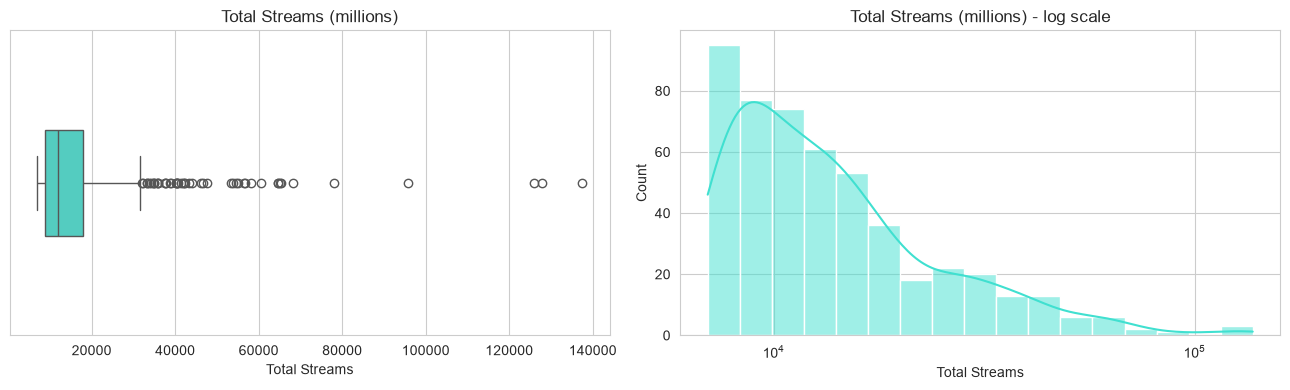

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=df, x='Total Streams', width=0.35, color='turquoise', ax=ax1)
ax1.set_title('Total Streams (millions)')

sns.histplot(data=df, x='Total Streams', log_scale=True, kde=True, color='turquoise', ax=ax2)
ax2.set_title('Total Streams (millions) - log scale')

plt.tight_layout()
plt.show()

The boxplot shows many outliers, but there are some very big artists (Drake, Taylor Swift, Bad Bunny, ...), not errors. Removing them would remove the most successful artists, which is exactly what we want to study. So we keep them and use the **median** and **log scales** in the analysis.

**Other checks.**

In [35]:
print('Debut years from', df['Debut Year'].min(), 'to', df['Debut Year'].max())

Debut years from 1939 to 2023


In [36]:
values_of_year=df['Year'].unique()
print(f'Values of Year:{values_of_year}')

Values of Year:[2026]


- Debut years go from 1939 (Frank Sinatra) to 2023, which makes sense.
- `Year` is always 2026 (the year the data was extracted). We keep it to calculate the career length.
- 4 entries are not musicians but brands or series (Disney, League of Legends, and the German audio series Die drei ??? and Bibi Blocksberg). They are part of the streaming ranking, so we keep them, but we mark them so we can leave them out when we talk about artists.

In [37]:
df['Is Artist'] = ~df['Artist Name'].isin(['Disney', 'League of Legends', 'Die drei ???', 'Bibi Blocksberg'])
df.head()

,Artist ID,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year,Is Artist
0,0,Drake,Male,Canada,English,Hip-Hop,Solo,2006,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01,2026,True
1,1,Taylor Swift,Female,United States,English,Pop,Solo,2006,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01,2026,True
2,2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01,2026,True
3,3,The Weeknd,Male,Canada,English,R&B,Solo,2009,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01,2026,True
4,4,Justin Bieber,Male,Canada,English,Pop,Solo,2009,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01,2026,True


In [38]:
print('Missing values:', df.isna().sum().sum())

Missing values: 0


**Summary of Q1:**

| Problem | Decision |
|---|---|
| 10 duplicated rows | Removed |
| 1 empty row (only ID) | Removed |
| 25 missing stream values | Calculated with Total = Solo + Collab and Total = Lead + Feature |
| 22 missing `Sex` (all groups) | New category `Mixed/Unknown` |
| Wrong data types | Converted to int / datetime |
| `Sertanjeo`, `Nu Metal`, `Scotland` | Replaced by `Sertanejo`, `Metal`, `United Kingdom` |
| Lead/Feature slightly above Total | Kept (very small differences) |
| Outliers | Kept (real superstars) |
| 4 brands/series | Kept and marked with `Is Artist` |

The final dataset has **500 artists and no missing values**.

In [39]:
df.to_csv('artist_streams_clean.csv', index=False)